# Guardião Financeiro · Dynamic Programming
## Recomendador de renegociação de dívidas (mochila 0/1)

**FIAP · Global Solution 2026.2 · CitizenTech · Engenharia de Software**

Equipe: Nicolas Tanajura (RM 568108) · Marcelo Toledo (RM 568397) · Rafael Benez (RM 574994)

Repositório: `<link do repositório>`

## 1. O problema

O **Guardião Financeiro** protege idosos e pessoas com pouco letramento digital contra golpes e superendividamento. No posto presencial, o atendente ajuda o cidadão a montar um **plano de renegociação**: cada credor oferece um acordo com uma parcela mensal e uma taxa menor, mas o cidadão não consegue aceitar todos.

O cenário é real e está piorando entre os idosos:

- O Brasil chegou a **84,2 milhões de inadimplentes** em setembro de 2026, e **20,1%** têm mais de 60 anos (Serasa).
- A inadimplência acima de 60 anos cresceu **10,7%** entre ago/2025 e ago/2026, a maior alta entre as faixas etárias (Serasa).
- Cada inadimplente tem em média **4 dívidas** em aberto, e 48% ganham até um salário mínimo (Serasa).

A Lei do Superendividamento (Lei 14.181/2021) proíbe que as parcelas consumam o **mínimo existencial** (R$ 600). Então o orçamento para acordos é limitado:

> **Pergunta que o algoritmo responde:** dentro do orçamento mensal, quais acordos aceitar para que a dívida total pare de crescer o máximo possível?

**Definição formal.** Entrada: `N` propostas de acordo, cada uma com parcela `pᵢ` (R$) e economia mensal de juros `eᵢ`; orçamento `W`. Saída: subconjunto `S` com `Σ pᵢ ≤ W` que maximiza `Σ eᵢ`. Cada acordo é aceito inteiro ou recusado: é o **problema da mochila 0/1**.

## 2. Fonte dos dados

| Dado | Valor usado | Fonte |
|---|---|---|
| Juros médios do cartão rotativo (PF) | 442,4% a.a. (jun/2026) | Banco Central, Estatísticas Monetárias e de Crédito ([Times Brasil, 30/07/2026](https://timesbrasil.com.br/brasil/juros-cartao-rotativo-4424-junho/); série [BCB 25477](https://dadosabertos.bcb.gov.br/dataset/25477-taxa-media-mensal-de-juros-das-operacoes-de-credito-com-recursos-livres---pessoas-fisicas---c)) |
| Juros médios do cartão parcelado | 191,4% a.a. (jun/2026) | Banco Central (mesma divulgação) |
| Juros médios do cheque especial | 139,8% a.a. (jun/2026) | Banco Central (mesma divulgação) |
| Juros do crédito pessoal não consignado | 116,8% a.a. (2025) | Banco Central ([LexLegal](https://lexlegal.com.br/?p=54878)) |
| Teto do consignado INSS | 1,85% a.m. | CNPS/INSS, vigente em out/2026 ([JB](https://www.jb.com.br/editorias/?p=872)) |
| Salário mínimo 2026 | R$ 1.621 | Decreto 12.797/2025 ([InfoMoney](https://www.infomoney.com.br/politica/quando-comeca-a-valer-o-novo-salario-minimo-governo-publica-valor-para-2026/)) |
| Mínimo existencial | R$ 600 | Decreto 11.150/2022 com redação do Decreto 11.567/2023, mantido pelo STF em 2026 ([STF](https://noticias.stf.jus.br/postsnoticias/governo-federal-deve-revisar-anualmente-valor-do-minimo-existencial-em-negociacoes-de-superendividamento/)) |
| Perfil da inadimplência | 84,2 mi; 20,1% acima de 60 anos | Serasa, Mapa da Inadimplência, set/2026 ([Tribuna de Jundiaí](https://tribunadejundiai.com.br/economia/inadimplencia-brasil-recorde-serasa/)) |
| Crescimento entre idosos | +10,7% em 12 meses | [Serasa, set/2026](https://www.serasa.com.br/imprensa/renegociacao-entre-idosos/) |
| Dívidas por inadimplente | média de 4 | Serasa, fev/2026 ([Jornal Grande Bahia](https://jornalgrandebahia.com.br/2026/03/inadimplencia-no-brasil-atinge-817-milhoes-e-cresce-38-em-uma-decada-aponta-serasa/)) |

**O que é simulado:** a persona (Dona Maria, 68 anos), os saldos devedores, o desconto de consignado e as propostas de acordo (taxa e parcela). As taxas atuais vêm das médias do Banco Central. As taxas dos acordos ficam entre o teto do consignado INSS (1,85% a.m.) e 3,5% a.m.

In [1]:
# Taxas médias anuais do Banco Central (pessoa física) -> taxa mensal equivalente
TAXAS_BCB_AA = {
    "rotativo":      4.424,   # 442,4% a.a. (jun/2026)
    "parcelado":     1.914,   # 191,4% a.a. (jun/2026)
    "cheque":        1.398,   # 139,8% a.a. (jun/2026)
    "pessoal":       1.168,   # 116,8% a.a. (2025)
}

def anual_para_mensal(taxa_aa):
    # (1 + i_mês)^12 = 1 + i_ano  ->  juros compostos
    return (1 + taxa_aa) ** (1 / 12) - 1

TAXA_MES = {k: anual_para_mensal(v) for k, v in TAXAS_BCB_AA.items()}
for modalidade, i in TAXA_MES.items():
    print(f"{modalidade:<10} {TAXAS_BCB_AA[modalidade]*100:6.1f}% a.a.  ->  {i*100:5.2f}% a.m.")

rotativo    442.4% a.a.  ->  15.13% a.m.
parcelado   191.4% a.a.  ->   9.32% a.m.
cheque      139.8% a.a.  ->   7.56% a.m.
pessoal     116.8% a.a.  ->   6.66% a.m.


## 3. Modelagem

**Cada proposta de acordo é um dicionário** (`credor`, `saldo`, `taxa_atual`, `taxa_acordo`, `parcela`) e as propostas ficam numa **lista**. O dicionário deixa cada campo com nome claro, e a lista dá acesso por índice `i`, que é exatamente como a DP percorre os itens. A economia mensal não é guardada: é calculada por uma função, para não ter dois valores divergentes.

**Benefício de cada acordo:** `economia mensal = saldo × (taxa atual − taxa do acordo)`, ou seja, quantos reais de juros deixam de entrar na dívida por mês.

**A tabela da DP é uma lista de listas** `dp[i][w]`, com `N+1` linhas (itens) e `W+1` colunas (orçamento em reais inteiros). Todos os estados são visitados, então a tabela densa com acesso O(1) por índice é mais simples e rápida que um dicionário. As escolhas são reconstruídas percorrendo a própria tabela de trás para frente, sem estrutura extra.

In [2]:
# Persona (dados simulados) ------------------------------------------------
RENDA = 1621             # aposentadoria de 1 salário mínimo (Decreto 12.797/2025)
MINIMO_EXISTENCIAL = 600 # Decreto 11.150/2022 com redação do 11.567/2023
CONSIGNADO_ATUAL = 401   # desconto de consignado que já sai do benefício
ORCAMENTO = RENDA - MINIMO_EXISTENCIAL - CONSIGNADO_ATUAL   # R$ 620

PROPOSTAS_DONA_MARIA = [
    {"credor": "Cartão Banco A (rotativo)",  "saldo": 2800, "taxa_atual": TAXA_MES["rotativo"],  "taxa_acordo": 0.030,  "parcela": 310},
    {"credor": "Cartão de loja (rotativo)",  "saldo": 1000, "taxa_atual": TAXA_MES["rotativo"],  "taxa_acordo": 0.035,  "parcela": 110},
    {"credor": "Cartão Banco B (rotativo)",  "saldo": 2600, "taxa_atual": TAXA_MES["rotativo"],  "taxa_acordo": 0.030,  "parcela": 310},
    {"credor": "Cartão Banco A (parcelado)", "saldo": 1900, "taxa_atual": TAXA_MES["parcelado"], "taxa_acordo": 0.029,  "parcela": 190},
    {"credor": "Cheque especial",            "saldo": 1500, "taxa_atual": TAXA_MES["cheque"],    "taxa_acordo": 0.025,  "parcela": 150},
    {"credor": "Empréstimo pessoal",         "saldo": 3000, "taxa_atual": TAXA_MES["pessoal"],   "taxa_acordo": 0.0185, "parcela": 230},
]

def economia_mensal(d):
    # Juros que deixam de entrar na dívida por mês ao aceitar o acordo
    return d["saldo"] * (d["taxa_atual"] - d["taxa_acordo"])

print(f"Orçamento para acordos: R$ {RENDA} - R$ {MINIMO_EXISTENCIAL} - R$ {CONSIGNADO_ATUAL} = R$ {ORCAMENTO}\n")
print(f"{'#':<3}{'Credor':<28}{'Saldo':>8}{'Atual':>8}{'Acordo':>8}{'Parcela':>9}{'Economia/mês':>14}")
for i, d in enumerate(PROPOSTAS_DONA_MARIA):
    print(f"{i:<3}{d['credor']:<28}{d['saldo']:>8}{d['taxa_atual']*100:>7.2f}%{d['taxa_acordo']*100:>7.2f}%"
          f"{d['parcela']:>9}{economia_mensal(d):>14.2f}")
print(f"\nSoma das parcelas: R$ {sum(d['parcela'] for d in PROPOSTAS_DONA_MARIA)}  (não cabe tudo em R$ {ORCAMENTO})")

Orçamento para acordos: R$ 1621 - R$ 600 - R$ 401 = R$ 620

#  Credor                         Saldo   Atual  Acordo  Parcela  Economia/mês
0  Cartão Banco A (rotativo)       2800  15.13%   3.00%      310        339.68
1  Cartão de loja (rotativo)       1000  15.13%   3.50%      110        116.31
2  Cartão Banco B (rotativo)       2600  15.13%   3.00%      310        315.41
3  Cartão Banco A (parcelado)      1900   9.32%   2.90%      190        122.02
4  Cheque especial                 1500   7.56%   2.50%      150         75.91
5  Empréstimo pessoal              3000   6.66%   1.85%      230        144.32

Soma das parcelas: R$ 1300  (não cabe tudo em R$ 620)


## 4. Algoritmo

**Subproblema:** `dp[i][w]` = maior economia mensal possível usando só as `i` primeiras propostas com parcelas somando no máximo `w` reais.

**Recorrência:** para a proposta `i`, com parcela `pᵢ` e economia `eᵢ`, há duas escolhas:

```
dp[i][w] = max( dp[i-1][w],                 # recusa o acordo i
                dp[i-1][w - pᵢ] + eᵢ )      # aceita o acordo i (só se pᵢ ≤ w)
```

**Casos base:** `dp[0][w] = 0` (sem propostas, nenhuma economia) e `dp[i][0] = 0`.

A resposta é `dp[N][W]`. Para descobrir **quais** acordos foram aceitos, voltamos pela tabela: se `dp[i][w] ≠ dp[i-1][w]`, o acordo `i` foi aceito e descontamos sua parcela de `w`.

In [3]:
def recomendar_acordos(propostas, orcamento):
    # Mochila 0/1 bottom-up. Retorna (índices dos acordos aceitos, economia mensal total).
    n, W = len(propostas), int(orcamento)

    # dp[i][w]: melhor economia com as i primeiras propostas e orçamento w
    dp = [[0.0] * (W + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        parcela = propostas[i - 1]["parcela"]
        economia = economia_mensal(propostas[i - 1])
        for w in range(W + 1):
            # >>> IDEIA CENTRAL: o melhor resultado com orçamento w vem de RECUSAR o acordo i
            #     (resposta da linha anterior) ou de ACEITÁ-LO (economia dele + melhor resultado
            #     com o orçamento que sobra). Cada subproblema é resolvido uma única vez.
            recusa = dp[i - 1][w]
            aceita = dp[i - 1][w - parcela] + economia if parcela <= w else -1
            dp[i][w] = max(recusa, aceita)

    # Reconstrução: volta pela tabela descobrindo quais acordos entraram
    aceitos, w = [], W
    for i in range(n, 0, -1):
        if dp[i][w] != dp[i - 1][w]:
            aceitos.append(i - 1)
            w -= propostas[i - 1]["parcela"]
    return sorted(aceitos), dp[n][W]

## 5. Exemplo de entrada e saída: Dona Maria

In [4]:
def mostrar_plano(propostas, orcamento):
    aceitos, economia = recomendar_acordos(propostas, orcamento)
    gasto = sum(propostas[i]["parcela"] for i in aceitos)
    print(f"Orçamento: R$ {orcamento}\n\nACEITAR:")
    for i in aceitos:
        d = propostas[i]
        print(f"  [{i}] {d['credor']:<28} parcela R$ {d['parcela']:>4}   economia R$ {economia_mensal(d):7.2f}/mês")
    print("RECUSAR POR ENQUANTO:")
    for i, d in enumerate(propostas):
        if i not in aceitos:
            print(f"  [{i}] {d['credor']}")
    print(f"\nParcelas: R$ {gasto}  |  sobra: R$ {orcamento - gasto}")
    print(f"Economia: R$ {economia:.2f} por mês  (~R$ {economia * 12:,.0f} em 12 meses)".replace(",", "."))
    return aceitos, economia

aceitos_dp, economia_dp = mostrar_plano(PROPOSTAS_DONA_MARIA, ORCAMENTO)

Orçamento: R$ 620

ACEITAR:
  [0] Cartão Banco A (rotativo)    parcela R$  310   economia R$  339.68/mês
  [2] Cartão Banco B (rotativo)    parcela R$  310   economia R$  315.41/mês
RECUSAR POR ENQUANTO:
  [1] Cartão de loja (rotativo)
  [3] Cartão Banco A (parcelado)
  [4] Cheque especial
  [5] Empréstimo pessoal

Parcelas: R$ 620  |  sobra: R$ 0
Economia: R$ 655.09 por mês  (~R$ 7.861 em 12 meses)


## 6. Por que não a escolha "intuitiva"?

A estratégia gulosa natural é aceitar primeiro o acordo com **mais economia por real de parcela**. Ela parece boa, mas falha: pega acordos pequenos que "travam" o orçamento e impedem uma combinação melhor.

In [5]:
def escolha_gulosa(propostas, orcamento):
    ordem = sorted(range(len(propostas)),
                   key=lambda i: economia_mensal(propostas[i]) / propostas[i]["parcela"], reverse=True)
    aceitos, gasto = [], 0
    for i in ordem:
        if gasto + propostas[i]["parcela"] <= orcamento:
            aceitos.append(i)
            gasto += propostas[i]["parcela"]
    return sorted(aceitos), sum(economia_mensal(propostas[i]) for i in aceitos)

aceitos_g, economia_g = escolha_gulosa(PROPOSTAS_DONA_MARIA, ORCAMENTO)
print(f"Gulosa: acordos {aceitos_g} -> R$ {economia_g:.2f}/mês")
print(f"DP:     acordos {aceitos_dp} -> R$ {economia_dp:.2f}/mês")
print(f"\nA DP evita R$ {economia_dp - economia_g:.2f} a mais de juros por mês "
      f"({(economia_dp / economia_g - 1) * 100:.0f}% melhor), ~R$ {(economia_dp - economia_g) * 12:.0f} em um ano.")

Gulosa: acordos [0, 1, 3] -> R$ 578.01/mês
DP:     acordos [0, 2] -> R$ 655.09/mês

A DP evita R$ 77.08 a mais de juros por mês (13% melhor), ~R$ 925 em um ano.


## 7. Testes

A **força bruta** testa todas as `2ᴺ` combinações e serve de gabarito: ela é lenta, mas certamente correta. Comparamos a DP com ela no caso da Dona Maria (em 121 orçamentos diferentes) e em 300 casos aleatórios, além de casos de borda.

In [6]:
import random
from math import isclose

def forca_bruta(propostas, orcamento):
    n, melhor = len(propostas), 0.0
    for mascara in range(1 << n):                 # cada bit = aceita/recusa um acordo
        parcelas = economia = 0
        for i in range(n):
            if mascara >> i & 1:
                parcelas += propostas[i]["parcela"]
                economia += economia_mensal(propostas[i])
        if parcelas <= orcamento:
            melhor = max(melhor, economia)
    return melhor

def proposta_aleatoria(rng):
    modalidade = rng.choice(list(TAXA_MES))
    return {"credor": modalidade, "saldo": rng.randrange(300, 5001, 50),
            "taxa_atual": TAXA_MES[modalidade], "taxa_acordo": rng.choice([0.0185, 0.025, 0.03, 0.035]),
            "parcela": rng.randrange(50, 401, 10)}

# 1) Dona Maria em vários orçamentos
for orc in range(0, 1201, 10):
    assert isclose(recomendar_acordos(PROPOSTAS_DONA_MARIA, orc)[1], forca_bruta(PROPOSTAS_DONA_MARIA, orc))
print("OK  DP = força bruta no caso Dona Maria (121 orçamentos)")

# 2) Casos aleatórios
rng = random.Random(2026)
for _ in range(300):
    props = [proposta_aleatoria(rng) for _ in range(rng.randint(1, 10))]
    orc = rng.randint(0, 1500)
    aceitos, eco = recomendar_acordos(props, orc)
    assert isclose(eco, forca_bruta(props, orc))                       # ótimo
    assert sum(props[i]["parcela"] for i in aceitos) <= orc           # respeita o orçamento
    assert isclose(eco, sum(economia_mensal(props[i]) for i in aceitos))  # reconstrução coerente
print("OK  DP = força bruta em 300 casos aleatórios (1 a 10 propostas)")

# 3) Casos de borda
assert recomendar_acordos([], 620) == ([], 0.0)                         # sem propostas
assert recomendar_acordos(PROPOSTAS_DONA_MARIA, 0) == ([], 0.0)         # sem orçamento
cara = [{"credor": "x", "saldo": 9000, "taxa_atual": 0.15, "taxa_acordo": 0.02, "parcela": 900}]
assert recomendar_acordos(cara, 620) == ([], 0.0)                       # parcela maior que o orçamento
assert recomendar_acordos(cara, 900)[0] == [0]                          # cabe exatamente
print("OK  casos de borda: lista vazia, orçamento zero, parcela acima do orçamento, parcela exata")

OK  DP = força bruta no caso Dona Maria (121 orçamentos)


OK  DP = força bruta em 300 casos aleatórios (1 a 10 propostas)
OK  casos de borda: lista vazia, orçamento zero, parcela acima do orçamento, parcela exata


## 8. Eficiência

| Abordagem | Tempo | Memória | Garante o ótimo? |
|---|---|---|---|
| Força bruta | O(2ᴺ · N) | O(1) | Sim |
| Gulosa | O(N log N) | O(N) | **Não** (seção 6) |
| **DP (mochila 0/1)** | **O(N · W)** | O(N · W) | **Sim** |

`N` é o número de propostas e `W` o orçamento em reais. A DP é **pseudo-polinomial**: depende do valor de `W`, não só da quantidade de itens. No nosso cenário isso é ótimo, porque o orçamento de um cidadão é pequeno (centenas de reais). Se usássemos centavos, `W` ficaria 100 vezes maior. Se não precisássemos reconstruir as escolhas, a memória cairia para O(W) com uma única linha.

A medição abaixo fixa o orçamento da Dona Maria (R$ 620) e aumenta o número de propostas:

    N     combinações   força bruta          DP
    4              16        0.000s       0.4ms
    8             256        0.000s       0.7ms
   12           4.096        0.005s       1.1ms
   14          16.384        0.021s       1.5ms
   16          65.536        0.098s       2.2ms


   18         262.144        0.440s       2.4ms
   50      (inviável)             -       4.3ms
  100      (inviável)             -       9.7ms
  500      (inviável)             -      43.4ms
 1000      (inviável)             -      87.2ms


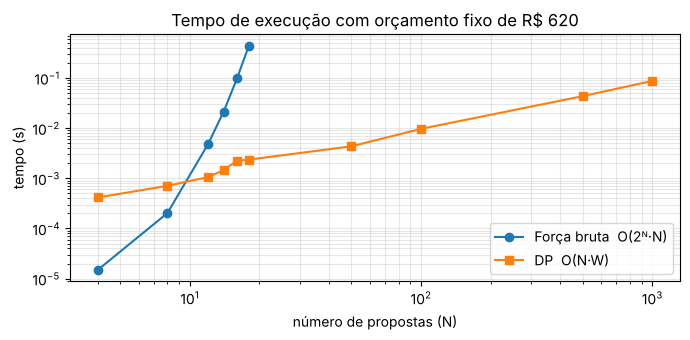

In [7]:
import time
import matplotlib.pyplot as plt

def cronometrar(funcao, *args):
    inicio = time.perf_counter()
    resultado = funcao(*args)
    return resultado, time.perf_counter() - inicio

rng = random.Random(7)
tamanhos_bruta = [4, 8, 12, 14, 16, 18]
tamanhos_dp = tamanhos_bruta + [50, 100, 500, 1000]
t_bruta, t_dp = {}, {}

print(f"{'N':>5}{'combinações':>16}{'força bruta':>14}{'DP':>12}")
for n in tamanhos_dp:
    props = [proposta_aleatoria(rng) for _ in range(n)]
    (_, eco_dp), t_dp[n] = cronometrar(recomendar_acordos, props, ORCAMENTO)
    if n in tamanhos_bruta:
        eco_b, t_bruta[n] = cronometrar(forca_bruta, props, ORCAMENTO)
        assert isclose(eco_b, eco_dp)
        print(f"{n:>5}{2**n:>16,}{t_bruta[n]:>13.3f}s{t_dp[n]*1000:>10.1f}ms".replace(",", "."))
    else:
        print(f"{n:>5}{'(inviável)':>16}{'-':>14}{t_dp[n]*1000:>10.1f}ms")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(list(t_bruta), list(t_bruta.values()), "o-", label="Força bruta  O(2ᴺ·N)")
ax.plot(list(t_dp), list(t_dp.values()), "s-", label="DP  O(N·W)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("número de propostas (N)"); ax.set_ylabel("tempo (s)")
ax.set_title("Tempo de execução com orçamento fixo de R$ 620")
ax.grid(True, which="both", alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

Com poucas propostas a força bruta até ganha (não monta tabela), mas a partir de umas 10 a DP passa na frente e a distância explode. Com 18 propostas a força bruta já testa 262 mil combinações. Com 30 seriam mais de 1 bilhão. A DP resolve 1.000 propostas em uma fração de segundo, porque o custo cresce de forma linear em `N` quando o orçamento é fixo.

## 9. Integração e limitações

**No Guardião Financeiro:** o módulo Java (DDD) envia as propostas recebidas dos credores e o orçamento calculado. Esta função devolve o plano, que o atendente do posto explica ao cidadão e o guardião (familiar cadastrado) aprova pelo app.

**Limitações:**
- A economia mensal é uma aproximação: não projeta a amortização mês a mês nem o teto de 100% de juros do rotativo (Lei 14.690/2023).
- As taxas atuais são médias do Banco Central, não as taxas reais do contrato de cada pessoa.
- Parcelas são tratadas em reais inteiros.